# 42. Trapping Rain Water
**Difficulty:** 🔴 Hard · **Topic:** Two Pointers · **Pattern:** [Opposite Ends](README.md) · **LeetCode:** https://leetcode.com/problems/trapping-rain-water/

## 💡 Concepts

**Core concept(s):** **water above one bar = `min(tallest wall on its left, tallest wall on its right) - its height`**, computed with **two pointers from opposite ends** that each carry a running max.

**Why it applies here:**
- Water over bar `i` is capped by the *lower* of the two tallest walls around it.
- So you only ever need two numbers per bar: the max to its left and the max to its right.
- Two pointers can supply those maxes on the fly: whichever side has the **smaller** running max is the side whose water level is already known.

**Key intuition:**
- Say `left_max < right_max`. The bar just inside `lo` has a right wall at least `right_max` tall, so its water level is decided by `left_max` alone.
- Fill that bar, move `lo` inward, repeat. Symmetric on the right.

---

### 📚 What is a Prefix Max / Suffix Max array? (used by Approach 2)
- A **prefix max** array stores, at each index `i`, the largest value in `height[0..i]`.
- A **suffix max** array stores, at each index `i`, the largest value in `height[i..n-1]`.
- Each is built in one pass: `left[i] = max(left[i-1], height[i])`, and the mirror image from the right.
- **Complexity:** `O(n)` time and `O(n)` space per array; afterwards any "tallest wall on my left/right" question is an `O(1)` lookup.
- **In Python:** two `list`s of length `n`.

### 📚 What is the Two-Pointer Technique (opposite ends)?
- Two integer indices, `lo` at the start and `hi` at the end, that walk toward each other.
- Each step looks at the two ends and moves exactly one pointer inward, chosen by a rule that proves the moved-past element is finished.
- They stop when they meet, so the loop runs at most `n - 1` times.
- **Complexity:** `O(n)` time, `O(1)` extra space.
- **In Python:** two `int` variables and a `while lo < hi:` loop.

### 📚 What is a running max?
- A single variable that remembers the largest value seen so far: `best = max(best, x)` on every step.
- `O(1)` per update, `O(1)` space.
- Here each pointer carries its own: `left_max` for everything `lo` has passed, `right_max` for everything `hi` has passed.

---

**Prerequisite knowledge:**
- [Container With Most Water](container_with_most_water.ipynb) — the same "the shorter side is the limit, so move it" argument.

## 📝 Problem

`height[i]` is the height of a bar of width 1. After it rains, how many units of water are trapped between the bars?

**Example 1** (used for the step-through on the interactive page)
```
height = [0,1,0,2,1,0,1,3,2,1,2,1]  ->  6
```

**Example 2**
```
height = [4,2,0,3,2,5]  ->  9

  5 |                #
  4 | #  ~  ~  ~  ~  #        ~ = water
  3 | #  ~  ~  #  ~  #        per bar: 0 + 2 + 4 + 1 + 2 + 0 = 9
  2 | #  #  ~  #  #  #
  1 | #  #  ~  #  #  #
      4  2  0  3  2  5
```

**Constraints:** `1 <= n <= 2 * 10^4`, `0 <= height[i] <= 10^5`.

> Three approaches: per-bar rescan (`O(n²)`), prefix/suffix max arrays (`O(n)` time, `O(n)` space), and opposite-end two pointers (`O(n)` time, `O(1)` space).

In [1]:
from typing import List

### Approach 1 — Brute Force: scan both sides of every bar

**Idea:**
1. For each bar `i`, scan left to find the tallest bar in `height[0..i]` and scan right for the tallest in `height[i..n-1]`.
2. Water above `i` is `min(left_tallest, right_tallest) - height[i]` (never negative, because both include `height[i]`).
3. Add it up.

**Time complexity:** `O(n²)` — every bar rescans the whole array.

**Space complexity:** `O(1)` — a few variables.

In [2]:
def trap_brute(height: List[int]) -> int:
    n = len(height)
    water = 0
    for i in range(n):
        left_tallest = max(height[:i + 1])     # tallest wall at or left of i (O(n) scan)
        right_tallest = max(height[i:])        # tallest wall at or right of i (O(n) scan)
        water += min(left_tallest, right_tallest) - height[i]   # the lower wall sets the water level
    return water

### Approach 2 — Prefix max and suffix max arrays

**Idea:** the brute force recomputes the same maxima over and over. Compute them once.
1. `left[i]` = tallest bar in `height[0..i]` (one pass left → right).
2. `right[i]` = tallest bar in `height[i..n-1]` (one pass right → left).
3. Water above `i` is `min(left[i], right[i]) - height[i]`.

**Time complexity:** `O(n)` — three linear passes.

**Space complexity:** `O(n)` — two extra arrays.

In [3]:
def trap_prefix_suffix(height: List[int]) -> int:
    n = len(height)
    if n == 0:
        return 0
    left = [0] * n
    right = [0] * n
    left[0] = height[0]
    for i in range(1, n):
        left[i] = max(left[i - 1], height[i])         # tallest wall seen from the left
    right[n - 1] = height[n - 1]
    for i in range(n - 2, -1, -1):
        right[i] = max(right[i + 1], height[i])       # tallest wall seen from the right
    return sum(min(left[i], right[i]) - height[i] for i in range(n))

### Approach 3 — Two Pointers with running maxes (optimal · pattern template)

**Idea:** the [Opposite Ends](README.md) template; the side with the **smaller running max** moves.
1. `lo = 0`, `hi = n - 1`, `left_max = height[lo]`, `right_max = height[hi]`.
2. If `left_max < right_max`: the bar at `lo + 1` has a right wall at least `right_max` tall, so its level is set by `left_max`. Step `lo` in, update `left_max`, add `left_max - height[lo]`.
3. Otherwise do the mirror step on the right.
4. Stop when the pointers meet. Each bar is filled exactly once, by whichever pointer reaches it.

**Time complexity:** `O(n)` — each step moves one pointer inward.

**Space complexity:** `O(1)` — the arrays of Approach 2 shrink to two running maxes.

In [4]:
def trap_two_pointers(height: List[int]) -> int:
    if not height:
        return 0
    lo, hi = 0, len(height) - 1                # one pointer at each end
    left_max, right_max = height[lo], height[hi]
    water = 0
    while lo < hi:
        if left_max < right_max:               # left side is the limit: its level is known
            lo += 1
            left_max = max(left_max, height[lo])
            water += left_max - height[lo]     # 0 when height[lo] is a new left_max
        else:                                  # right side is the limit (or a tie)
            hi -= 1
            right_max = max(right_max, height[hi])
            water += right_max - height[hi]
    return water

In [5]:
# Correctness check
import random

tests = [
    ([0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1], 6),   # LeetCode example 1
    ([4, 2, 0, 3, 2, 5], 9),                     # LeetCode example 2 (the step-through)
    ([5], 0),                                    # single bar
    ([1, 2, 3, 4, 5], 0),                        # strictly rising: nothing can be held
    ([5, 4, 3, 2, 1], 0),                        # strictly falling
    ([3, 0, 3], 3),                              # one pit
    ([2, 0, 2, 0, 2], 4),                        # two pits, equal walls
    ([0, 0, 0], 0),                              # flat ground
]
for h, exp in tests:
    a, b, c = trap_brute(h), trap_prefix_suffix(h), trap_two_pointers(h)
    print(f"{str(h):38} -> {c}")
    assert a == b == c == exp, f"mismatch on {h}: brute={a} prefix={b} two_pointers={c}"

# Randomised cross-check
rng = random.Random(42)
for _ in range(500):
    h = [rng.randint(0, 9) for _ in range(rng.randint(1, 40))]
    assert trap_brute(h) == trap_prefix_suffix(h) == trap_two_pointers(h), h
print("500 random skylines: all three approaches agree")

print("\nAll tests passed")

[0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1]   -> 6
[4, 2, 0, 3, 2, 5]                     -> 9
[5]                                    -> 0
[1, 2, 3, 4, 5]                        -> 0
[5, 4, 3, 2, 1]                        -> 0
[3, 0, 3]                              -> 3
[2, 0, 2, 0, 2]                        -> 4
[0, 0, 0]                              -> 0
500 random skylines: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

No approach can exit early here: every one must look at every bar. The input is a bumpy skyline with small values (`(7*i) % 11`), so there is water to collect and the arithmetic stays `O(1)`. The brute force rescans the array for each bar, so it should show ≈4×; the other two should show ≈2×.


brute         O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       6.89 |           n/a
     2000 |      24.47 |         3.55x
     4000 |      98.05 |         4.01x


     8000 |     409.61 |         4.18x

prefix/suffix O(n)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.19 |           n/a
     2000 |       0.37 |         1.93x
     4000 |       0.76 |         2.07x
     8000 |       1.80 |         2.38x

two pointers  O(n)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.12 |           n/a
     2000 |       0.24 |         2.02x
     4000 |       0.49 |         2.03x
     8000 |       0.66 |         1.36x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


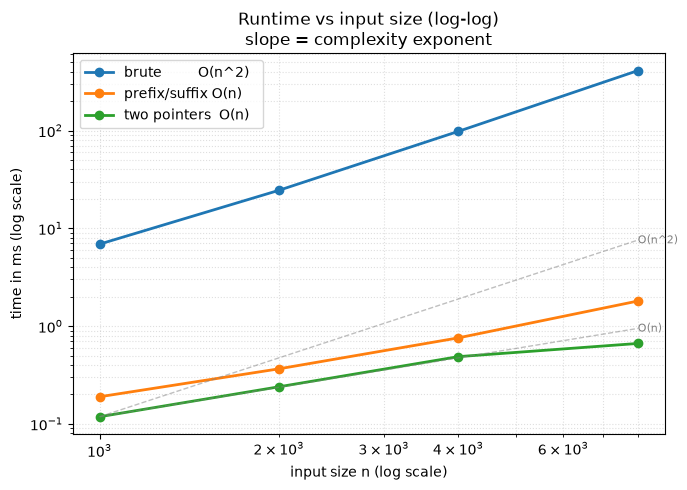

{'brute         O(n^2)': [6.886875024065375,
  24.472667020745575,
  98.04933390114456,
  409.611624898389],
 'prefix/suffix O(n)  ': [0.18933298997581005,
  0.3655829932540655,
  0.7578330114483833,
  1.8034999957308173],
 'two pointers  O(n)  ': [0.118291936814785,
  0.2394999610260129,
  0.4871250130236149,
  0.6643750239163637]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def make_worst_case(n):
    return ([(7 * i) % 11 for i in range(n)],)   # bumpy skyline, values 0..10

solutions = {
    "brute         O(n^2)": trap_brute,
    "prefix/suffix O(n)  ": trap_prefix_suffix,
    "two pointers  O(n)  ": trap_two_pointers,
}
sizes = [1000, 2000, 4000, 8000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Opposite Ends](README.md) — each pointer carries a running max, and the side with the smaller max moves, because that side's water level is already decided.
- **"Per-element answer = f(max on the left, max on the right)" → prefix/suffix maxima:** precompute both arrays (`O(n)` space), then notice that only the smaller side matters at each step, which lets two pointers replace both arrays (`O(1)` space).
- **Same argument as Container With Most Water:** the shorter side is the limit, so the shorter side is the one you can finalise and move past.
- **Signal:** "how much water / rain is trapped", "elevation map", "bars of width 1", a value bounded by the lower of two walls.
- **Related problems:** Container With Most Water, Product of Array Except Self (prefix/suffix idea), Largest Rectangle in Histogram (a bars problem that needs a different technique).
- **Common pitfalls:**
  1. Adding `left_max - height[lo]` *before* updating `left_max` — it goes negative when `height[lo]` is a new max.
  2. Moving the side with the *larger* max — its level is not known yet.
  3. Confusing it with Container With Most Water: there you pick **one** pair of walls; here every bar holds its own column of water.